# Aplicación práctica - Modelado de un circuito RC (45 min)
## Problema:
En un circuito RC serie con R=1kΩ, C=100μF, y entrada escalón de 5V, calcular y graficar $$V_c(t) = V_{in} * (1 - e^{-t/τ})$$ para $t=0$ a 5τ.

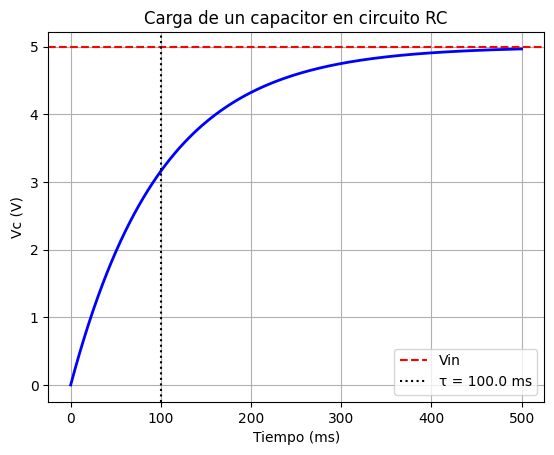

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros
R = 1000      # ohms
C = 100e-6    # faradios
tau = R * C   # constante de tiempo
Vin = 5       # voltios

# Tiempo
t = np.linspace(0, 5*tau, 200)

# Ecuación de carga del capacitor
Vc = Vin * (1 - np.exp(-t / tau))

# Gráfica
plt.plot(t*1000, Vc, 'b-', linewidth=2)
plt.axhline(y=Vin, color='r', linestyle='--', label='Vin')
plt.axvline(x=tau*1000, color='k', linestyle=':', label=f'τ = {tau*1000:.1f} ms')
plt.xlabel('Tiempo (ms)')
plt.ylabel('Vc (V)')
plt.title('Carga de un capacitor en circuito RC')
plt.legend()
plt.grid(True)
plt.show()

### Ejemplo: Circuito RC - Carga y descarga del capacitor
### Modelado matemático y gráfico

In [ ]:
"""
Ejemplo: Circuito RC - Carga y descarga del capacitor
Modelado matemático y gráfico
"""

import numpy as np
import matplotlib.pyplot as plt

def voltaje_carga(t, Vin, tau):
    """Voltaje en capacitor durante carga: Vc = Vin * (1 - e^(-t/τ))"""
    return Vin * (1 - np.exp(-t / tau))

def voltaje_descarga(t, Vin, tau):
    """Voltaje en capacitor durante descarga: Vc = Vin * e^(-t/τ)"""
    return Vin * np.exp(-t / tau)

def graficar_carga_descarga(R, C, Vin, tiempo_total=None):
    """Grafica proceso de carga y descarga"""
    tau = R * C

    if tiempo_total is None:
        tiempo_total = 5 * tau

    t = np.linspace(0, tiempo_total, 500)

    # Simular carga y luego descarga
    t_carga = t[t <= tiempo_total/2]
    t_descarga = t[t > tiempo_total/2] - tiempo_total/2

    V_carga = voltaje_carga(t_carga, Vin, tau)
    V_descarga = voltaje_descarga(t_descarga, Vin, tau)

    t_completo = np.concatenate([t_carga, t_descarga + tiempo_total/2])
    V_completo = np.concatenate([V_carga, V_descarga])

    # Gráfica
    plt.figure(figsize=(10, 6))
    plt.plot(t_completo*1000, V_completo, 'b-', linewidth=2)
    plt.axhline(y=Vin, color='r', linestyle='--', label=f'Vin = {Vin}V')
    plt.axvline(x=tau*1000, color='g', linestyle=':', label=f'τ = {tau*1000:.2f}ms')
    plt.xlabel('Tiempo (ms)')
    plt.ylabel('Voltaje (V)')
    plt.title(f'Circuito RC: R={R/1000:.1f}kΩ, C={C*1e6:.0f}μF')
    plt.legend()
    plt.grid(True)
    plt.show()

    return tau

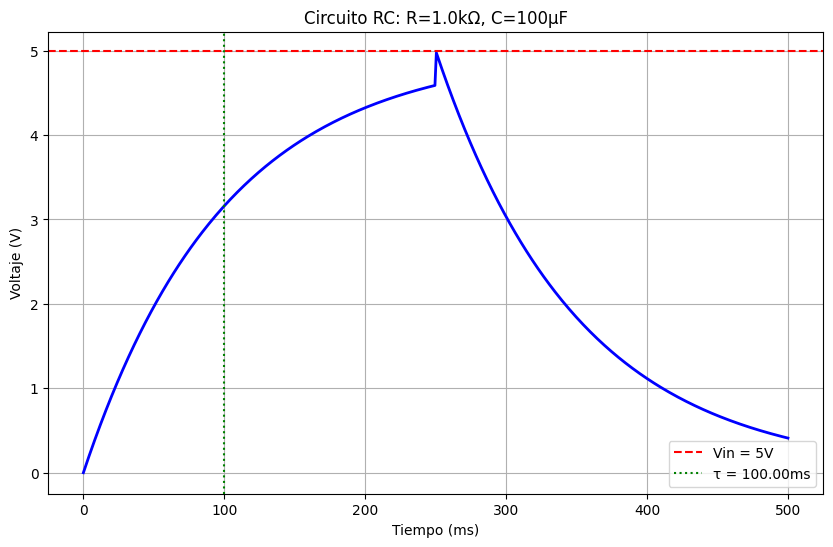

Constante de tiempo τ = 100.00 ms
Tiempo de estabilización (5τ) = 500.00 ms


In [ ]:
  R = 1000      # 1kΩ
  C = 100e-6    # 100μF
  Vin = 5       # 5V

  tau = graficar_carga_descarga(R, C, Vin)
  print(f"Constante de tiempo τ = {tau*1000:.2f} ms")
  print(f"Tiempo de estabilización (5τ) = {5*tau*1000:.2f} ms")

## Ejercicios Propuestos (30 min)

1. Calcular la potencia disipada en una resistencia dado voltaje y corriente.
Subir como ejercicios/ejercicio1.py
2. Graficar una señal cuadrada (usando scipy.signal.square o una función manual) con frecuencia 100 Hz y ciclo de trabajo 25%.
Subir como ejercicios/ejercicio2.py.
3. Simular la respuesta de un filtro pasa bajos RC de primer orden a una entrada senoidal de 10 Hz y 100 Hz. Graficar entrada y salida. Subir como ejercicios/ejercicio3.py

## Subir las respuestas a Github

```console
git add .
git commit -m "Agrega ejercicios sesion1 - modelado RC y señales"
git push origin main
```

## Ejemplo: Transformada Rápida de Fourier (FFT) básica
### Análisis espectral de señales en electrónica

Frecuencia de muestreo: 2000 Hz
Resolución espectral: 2.00 Hz


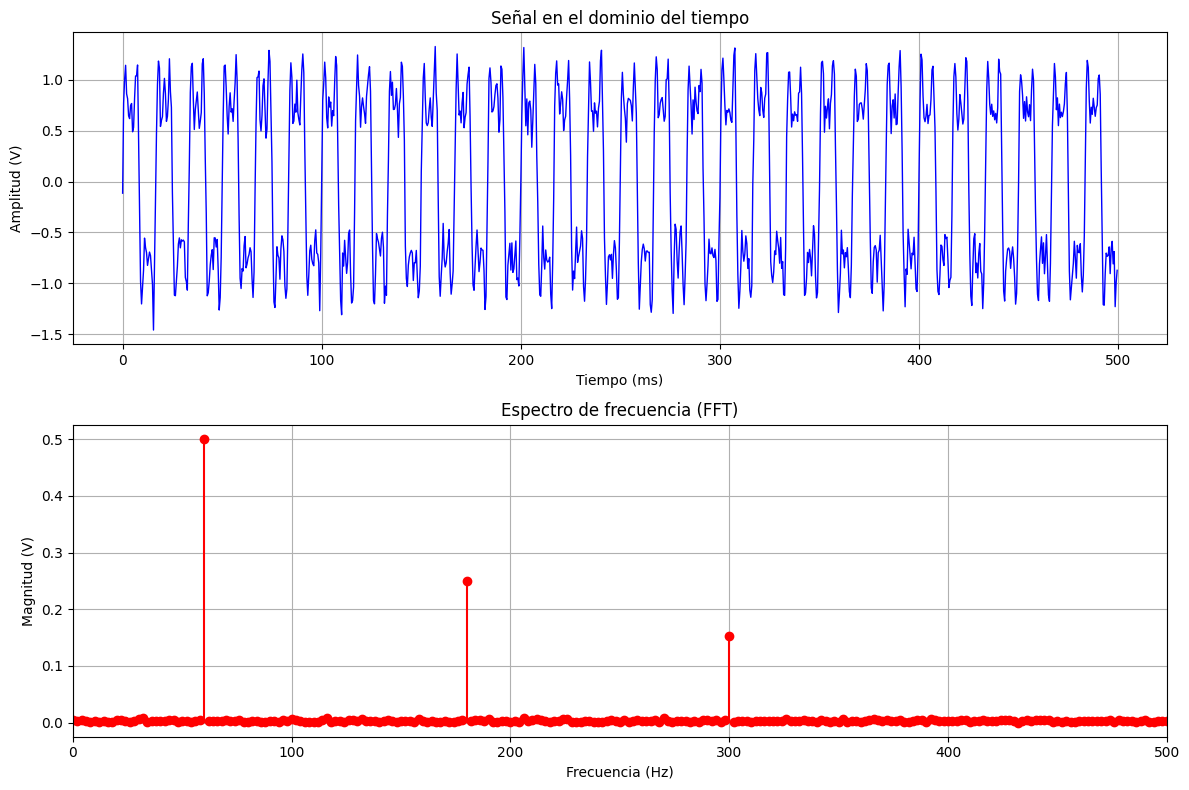


--- Componentes frecuenciales detectadas ---
Frecuencia: 60.0 Hz, Amplitud: 0.500 V
Frecuencia: 180.0 Hz, Amplitud: 0.250 V
Frecuencia: 300.0 Hz, Amplitud: 0.152 V


In [ ]:
"""
Ejemplo: Transformada Rápida de Fourier (FFT) básica
Análisis espectral de señales en electrónica
"""

import numpy as np
import matplotlib.pyplot as plt

def generar_senal_compuesta(fs, duracion):
    """
    Genera una señal compuesta por múltiples frecuencias
    Simula vibraciones o armónicos en circuitos
    """
    t = np.arange(0, duracion, 1/fs)

    # Señal base 60 Hz (frecuencia de red)
    senal = np.sin(2 * np.pi * 60 * t)

    # Agregar armónico de 180 Hz (3er armónico)
    senal += 0.5 * np.sin(2 * np.pi * 180 * t)

    # Agregar interferencia de 300 Hz (5to armónico)
    senal += 0.3 * np.sin(2 * np.pi * 300 * t)

    # Ruido aleatorio bajo
    senal += 0.1 * np.random.randn(len(t))

    return t, senal

def calcular_fft(senal, fs):
    """
    Calcula FFT y retorna frecuencias y espectro de magnitud
    """
    N = len(senal)
    # FFT
    espectro_complejo = np.fft.fft(senal)
    # Frecuencias correspondientes
    frecuencias = np.fft.fftfreq(N, 1/fs)

    # Tomar solo la mitad positiva (frecuencias reales)
    N_pos = N // 2
    frecuencias_pos = frecuencias[:N_pos]
    magnitud_pos = np.abs(espectro_complejo[:N_pos]) / N

    return frecuencias_pos, magnitud_pos

def graficar_tiempo_frecuencia(t, senal, fs):
    """
    Muestra la señal en dominio del tiempo y frecuencia
    """
    freqs, mag = calcular_fft(senal, fs)

    # Crear figura con dos subplots
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

    # Dominio del tiempo
    ax1.plot(t * 1000, senal, 'b-', linewidth=1)
    ax1.set_xlabel('Tiempo (ms)')
    ax1.set_ylabel('Amplitud (V)')
    ax1.set_title('Señal en el dominio del tiempo')
    ax1.grid(True)

    # Dominio de la frecuencia (espectro)
    ax2.stem(freqs, mag, basefmt=" ", linefmt='r-', markerfmt='ro')
    ax2.set_xlabel('Frecuencia (Hz)')
    ax2.set_ylabel('Magnitud (V)')
    ax2.set_title('Espectro de frecuencia (FFT)')
    ax2.set_xlim(0, 500)  # Limitar a 500Hz para ver detalles
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    # Parámetros de muestreo (Teorema de Nyquist)
    fs = 2000  # Frecuencia de muestreo: 2 kHz (suficiente para frecuencias hasta 1 kHz)
    duracion = 0.5  # 500 ms

    print(f"Frecuencia de muestreo: {fs} Hz")
    print(f"Resolución espectral: {1/duracion:.2f} Hz")

    # Generar y analizar señal
    t, senal = generar_senal_compuesta(fs, duracion)
    graficar_tiempo_frecuencia(t, senal, fs)

    # Identificar componentes frecuenciales
    freqs, mag = calcular_fft(senal, fs)
    print("\n--- Componentes frecuenciales detectadas ---")
    for i in range(len(freqs)):
        if mag[i] > 0.05:  # Umbral para ignorar ruido
            print(f"Frecuencia: {freqs[i]:.1f} Hz, Amplitud: {mag[i]:.3f} V")

## Ejemplo: Densidad espectral de potencia (PSD)
### Útil para análisis de ruido en circuitos y señales de sensores

Análisis de densidad espectral de potencia
Simulando sensor de temperatura con ruido...



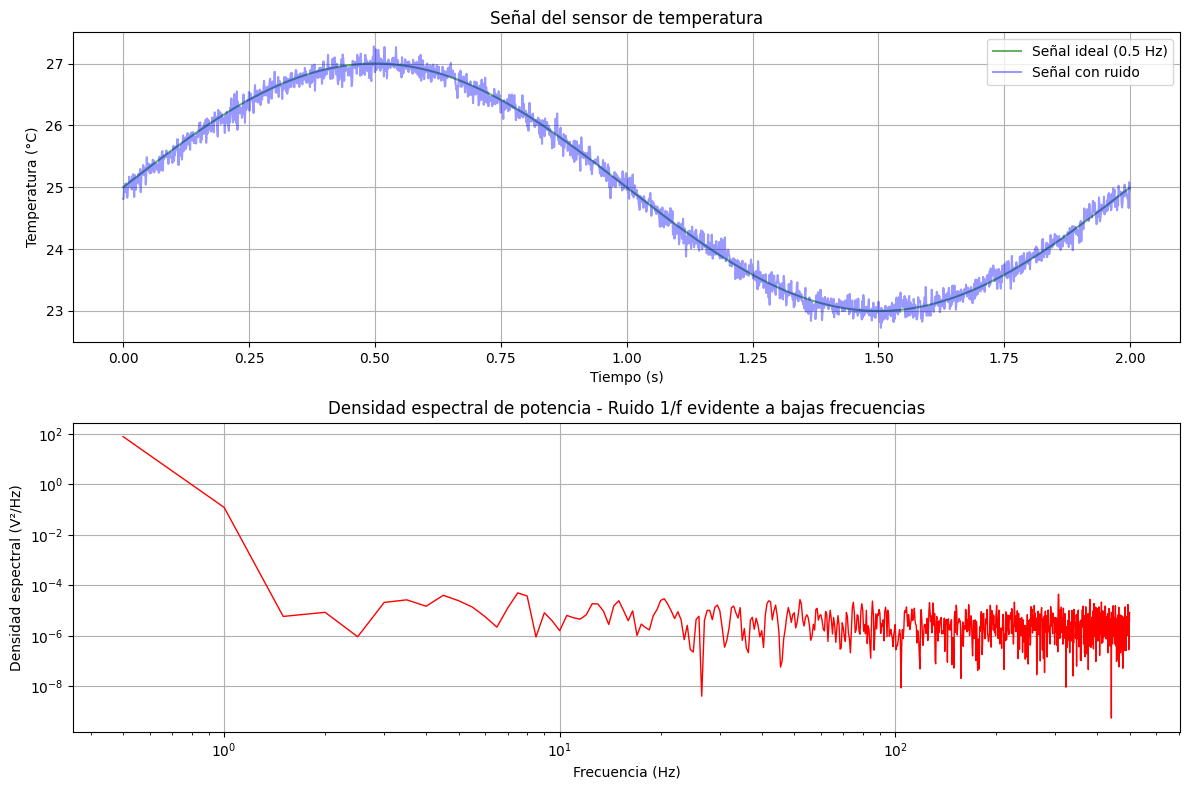

Relación señal/ruido (SNR): 22.1 dB
Potencia de ruido: 0.0122 V²


In [ ]:
"""
Ejemplo: Densidad espectral de potencia (PSD)
Útil para análisis de ruido en circuitos y señales de sensores
"""

import numpy as np
import matplotlib.pyplot as plt

def generar_ruido_1f(N, fs):
    """
    Genera ruido rosa (1/f) común en componentes electrónicos
    """
    freqs = np.fft.fftfreq(N, 1/fs)
    freqs[0] = 1  # Evitar división por cero

    # Espectro con amplitud 1/√f
    espectro_ruido = np.random.randn(N) + 1j * np.random.randn(N)
    espectro_ruido = espectro_ruido / np.sqrt(np.abs(freqs))

    # Transformada inversa para obtener señal en tiempo
    ruido = np.fft.ifft(espectro_ruido).real
    ruido = ruido / np.std(ruido)  # Normalizar
    return ruido

def calcular_psd(senal, fs):
    """
    Calcula la densidad espectral de potencia usando el método de Welch simplificado
    """
    N = len(senal)
    # Ventana de Hann para reducir leakage espectral
    ventana = np.hanning(N)
    senal_ventaneada = senal * ventana

    # FFT
    espectro = np.fft.fft(senal_ventaneada)
    espectro = espectro[:N//2]

    # Densidad espectral de potencia (V²/Hz)
    psd = (np.abs(espectro)**2) / (fs * N)
    freqs = np.fft.fftfreq(N, 1/fs)[:N//2]

    return freqs, psd

def simular_senal_sensor():
    """
    Simula la salida de un sensor de temperatura con ruido
    """
    fs = 1000  # Hz
    duracion = 2  # segundos
    t = np.arange(0, duracion, 1/fs)

    # Señal útil: variación lenta de temperatura (0.5 Hz)
    senal_util = 25 + 2 * np.sin(2 * np.pi * 0.5 * t)

    # Ruido térmico (Johnson-Nyquist)
    ruido_termico = np.random.randn(len(t)) * 0.1

    # Ruido de 1/f (flicker)
    ruido_flicker = generar_ruido_1f(len(t), fs) * 0.05

    senal_total = senal_util + ruido_termico + ruido_flicker

    return t, senal_total, senal_util

if __name__ == "__main__":
    print("Análisis de densidad espectral de potencia")
    print("Simulando sensor de temperatura con ruido...\n")

    # Generar señal
    t, senal, senal_ideal = simular_senal_sensor()
    fs = 1000

    # Calcular PSD
    freqs, psd = calcular_psd(senal, fs)

    # Gráfica
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

    # Señal en tiempo
    ax1.plot(t, senal_ideal, 'g-', alpha=0.6, label='Señal ideal (0.5 Hz)')
    ax1.plot(t, senal, 'b-', alpha=0.4, label='Señal con ruido')
    ax1.set_xlabel('Tiempo (s)')
    ax1.set_ylabel('Temperatura (°C)')
    ax1.set_title('Señal del sensor de temperatura')
    ax1.legend()
    ax1.grid(True)

    # Densidad espectral de potencia
    ax2.loglog(freqs[1:], psd[1:], 'r-', linewidth=1)
    ax2.set_xlabel('Frecuencia (Hz)')
    ax2.set_ylabel('Densidad espectral (V²/Hz)')
    ax2.set_title('Densidad espectral de potencia - Ruido 1/f evidente a bajas frecuencias')
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

    # Análisis del ruido
    potencia_ruido = np.var(senal - senal_ideal)
    snr_db = 10 * np.log10(np.var(senal_ideal) / potencia_ruido)
    print(f"Relación señal/ruido (SNR): {snr_db:.1f} dB")
    print(f"Potencia de ruido: {potencia_ruido:.4f} V²")

## Ejemplo: Filtrado en el dominio de la frecuencia
### Eliminación de interferencias usando FFT

Eliminación de interferencia de 60 Hz usando FFT


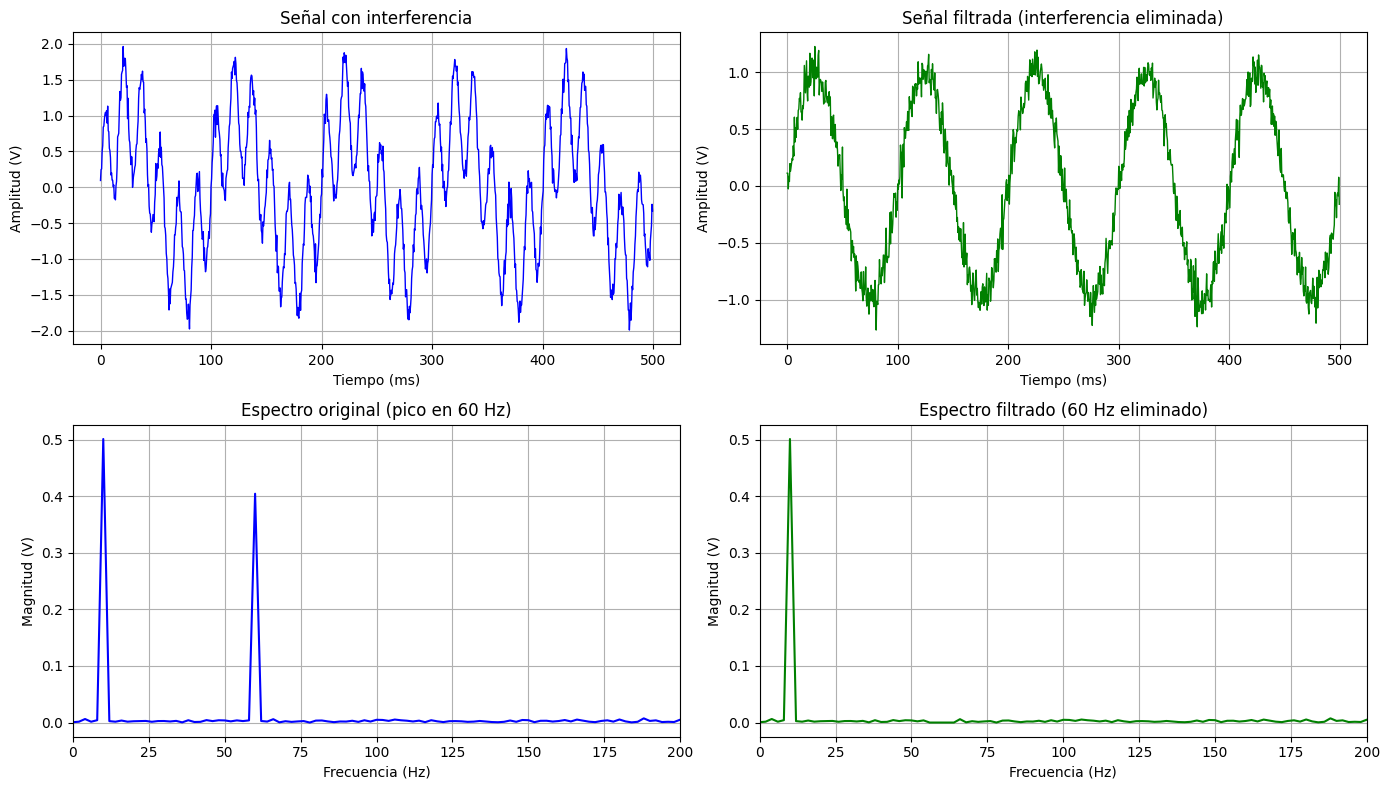


Error cuadrático medio original: 0.3367
Error cuadrático medio filtrado: 0.0096
Mejora: 15.4 dB


In [ ]:
"""
Ejemplo: Filtrado en el dominio de la frecuencia
Eliminación de interferencias usando FFT
"""

import numpy as np
import matplotlib.pyplot as plt

def aplicar_filtro_fft(senal, fs, frecuencias_eliminar, ancho_banda=5):
    """
    Elimina frecuencias específicas usando FFT
    Útil para eliminar interferencia de línea (50/60 Hz) y armónicos
    """
    N = len(senal)
    espectro = np.fft.fft(senal)
    freqs = np.fft.fftfreq(N, 1/fs)

    # Crear filtro (máscara)
    filtro = np.ones(N, dtype=complex)

    for f_eliminar in frecuencias_eliminar:
        # Encontrar índices cercanos a la frecuencia a eliminar
        mascara = np.abs(np.abs(freqs) - f_eliminar) < ancho_banda
        filtro[mascara] = 0

    # Aplicar filtro
    espectro_filtrado = espectro * filtro

    # Transformada inversa
    senal_filtrada = np.fft.ifft(espectro_filtrado).real

    return senal_filtrada

def generar_senal_con_interferencia():
    """
    Genera una señal senoidal de 10 Hz con interferencia de 60 Hz
    """
    fs = 2000
    duracion = 0.5
    t = np.arange(0, duracion, 1/fs)

    # Señal útil (10 Hz)
    senal_util = 1.0 * np.sin(2 * np.pi * 10 * t)

    # Interferencia de 60 Hz (frecuencia de red)
    interferencia = 0.8 * np.sin(2 * np.pi * 60 * t)

    # Ruido aleatorio
    ruido = 0.1 * np.random.randn(len(t))

    senal_total = senal_util + interferencia + ruido

    return t, senal_total, senal_util

def graficar_comparacion(t, senal_original, senal_filtrada, fs):
    """
    Compara señal original vs filtrada en tiempo y frecuencia
    """
    # Calcular FFT de ambas señales
    freqs = np.fft.fftfreq(len(t), 1/fs)[:len(t)//2]
    fft_orig = np.abs(np.fft.fft(senal_original))[:len(t)//2] / len(t)
    fft_filt = np.abs(np.fft.fft(senal_filtrada))[:len(t)//2] / len(t)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    # Señal original en tiempo
    axes[0, 0].plot(t * 1000, senal_original, 'b-', linewidth=1)
    axes[0, 0].set_xlabel('Tiempo (ms)')
    axes[0, 0].set_ylabel('Amplitud (V)')
    axes[0, 0].set_title('Señal con interferencia')
    axes[0, 0].grid(True)

    # Señal filtrada en tiempo
    axes[0, 1].plot(t * 1000, senal_filtrada, 'g-', linewidth=1)
    axes[0, 1].set_xlabel('Tiempo (ms)')
    axes[0, 1].set_ylabel('Amplitud (V)')
    axes[0, 1].set_title('Señal filtrada (interferencia eliminada)')
    axes[0, 1].grid(True)

    # Espectro original
    axes[1, 0].plot(freqs, fft_orig, 'b-')
    axes[1, 0].set_xlabel('Frecuencia (Hz)')
    axes[1, 0].set_ylabel('Magnitud (V)')
    axes[1, 0].set_title('Espectro original (pico en 60 Hz)')
    axes[1, 0].set_xlim(0, 200)
    axes[1, 0].grid(True)

    # Espectro filtrado
    axes[1, 1].plot(freqs, fft_filt, 'g-')
    axes[1, 1].set_xlabel('Frecuencia (Hz)')
    axes[1, 1].set_ylabel('Magnitud (V)')
    axes[1, 1].set_title('Espectro filtrado (60 Hz eliminado)')
    axes[1, 1].set_xlim(0, 200)
    axes[1, 1].grid(True)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    print("Eliminación de interferencia de 60 Hz usando FFT")

    # Generar señal
    t, senal_sucia, senal_limpia = generar_senal_con_interferencia()
    fs = 2000

    # Aplicar filtro
    frecuencias_a_eliminar = [60]  # Eliminar 60 Hz
    senal_filtrada = aplicar_filtro_fft(senal_sucia, fs, frecuencias_a_eliminar)

    # Graficar resultados
    graficar_comparacion(t, senal_sucia, senal_filtrada, fs)

    # Calcular mejora
    error_original = np.mean((senal_sucia - senal_limpia)**2)
    error_filtrado = np.mean((senal_filtrada - senal_limpia)**2)
    mejora_db = 10 * np.log10(error_original / error_filtrado)

    print(f"\nError cuadrático medio original: {error_original:.4f}")
    print(f"Error cuadrático medio filtrado: {error_filtrado:.4f}")
    print(f"Mejora: {mejora_db:.1f} dB")

## Aplicaciones adicionales de Python en Ingeniería Eléctrica/Electrónica
### 1. Simulación de Circuitos Eléctricos (SPICE-like)

In [ ]:
# 1. Install the ngspice circuit simulator backend binaries
!apt-get install -y ngspice libngspice0-dev

# 2. Install PySpice library
!pip install PySpice

# 3. Verify the installation is correct
!pyspice-post-installation --check-install

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libngspice0
Suggested packages:
  ngspice-doc
The following NEW packages will be installed:
  libngspice0 libngspice0-dev ngspice
0 upgraded, 3 newly installed, 0 to remove and 3 not upgraded.
Need to get 4,624 kB of archives.
After this operation, 15.5 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 libngspice0 amd64 36+ds-1ubuntu0.1 [2,256 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 libngspice0-dev amd64 36+ds-1ubuntu0.1 [15.6 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 ngspice amd64 36+ds-1ubuntu0.1 [2,352 kB]
Fetched 4,624 kB in 0s (24.7 MB/s)
Selecting previously unselected package libngspice0:amd64.
(Reading database ... 118243 files and directories currently installed.)
Preparing to unpack .../libngspice0_36+ds-1u

In [ ]:
import PySpice.Logging.Logging as Logging
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

circuit = Circuit('Circuito RLC serie')
circuit.R(1, 1, 2, 10@u_kOhm)
circuit.L(1, 2, 3, 100@u_mH)
circuit.C(1, 3, 0, 1@u_uF)
circuit.V(1, 1, 0, 5@u_V)

simulator = circuit.simulator(temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=50@u_ms)

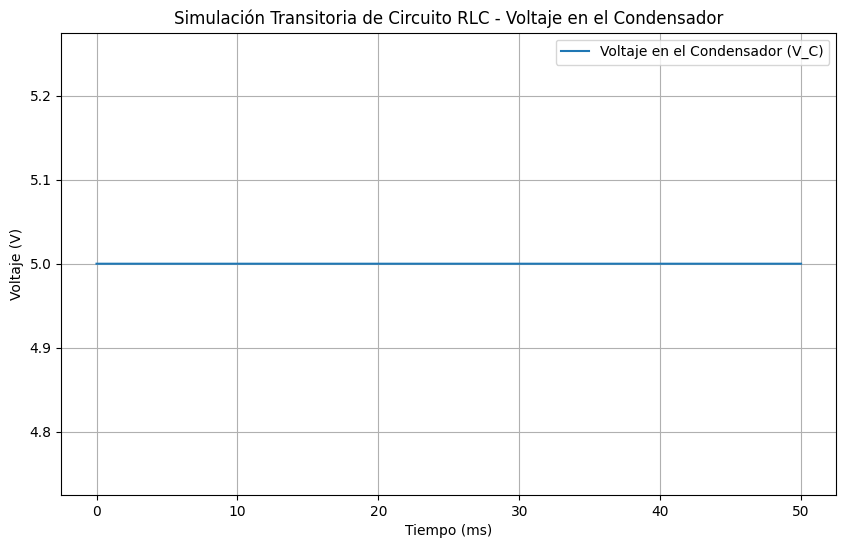

In [ ]:
import matplotlib.pyplot as plt

# Obtener el tiempo del análisis
time = analysis.time

# Obtener el voltaje en el nodo 3 (entre el condensador y la inductancia)
v_capacitor = analysis['3']

# Graficar el voltaje del condensador vs. tiempo
plt.figure(figsize=(10, 6))
plt.plot(time * 1e3, v_capacitor, label='Voltaje en el Condensador (V_C)')
plt.xlabel('Tiempo (ms)')
plt.ylabel('Voltaje (V)')
plt.title('Simulación Transitoria de Circuito RLC - Voltaje en el Condensador')
plt.grid(True)
plt.legend()
plt.show()

## 2. Flujo de Carga en Sistemas de Potencia (Power Flow)

In [ ]:
# Install pandapower if not already installed
!pip install pandapower

In [ ]:
import pandapower as pp

# Crear red eléctrica simple
net = pp.create_empty_network()

# Agregar bus de distribución
bus1 = pp.create_bus(net, vn_kv=13.8, name="Bus Principal")
bus2 = pp.create_bus(net, vn_kv=0.48, name="Bus Carga")

# Agregar una red externa (external grid) al bus principal para establecerlo como bus de referencia (slack bus)
# Esto es necesario para que pandapower pueda resolver el flujo de carga.
pp.create_ext_grid(net, bus=bus1, vm_pu=1.0, va_degree=0, name="Red Externa")

# Parámetros del transformador (valores típicos para 0.4 MVA 13.8/0.48 kV)
sn_mva = 0.4         # Potencia aparente nominal en MVA
vn_hv_kv = 13.8      # Voltaje nominal del lado de alta tensión en kV
vn_lv_kv = 0.48      # Voltaje nominal del lado de baja tensión en kV
vk_percent = 6       # Voltaje de cortocircuito en porcentaje
vkr_percent = 0.6    # Parte real del voltaje de cortocircuito en porcentaje
pfe_kw = 0.5         # Pérdidas en vacío (pérdidas en el hierro) en kW
i0_percent = 0.5     # Corriente en vacío en porcentaje

# Usar create_transformer_from_parameters para definir un transformador con parámetros personalizados
pp.create_transformer_from_parameters(net, hv_bus=bus1, lv_bus=bus2, sn_mva=sn_mva,
                                       vn_hv_kv=vn_hv_kv, vn_lv_kv=vn_lv_kv,
                                       vk_percent=vk_percent, vkr_percent=vkr_percent,
                                       pfe_kw=pfe_kw, i0_percent=i0_percent,
                                       name="Transformador Principal")

# Carga industrial
pp.create_load(net, bus2, p_mw=0.3, q_mvar=0.15)

# Resolver flujo de carga
pp.runpp(net)

# Resultados
print(f"Voltaje en carga: {net.res_bus.vm_pu[1]:.3f} pu")
print(f"Pérdidas totales: {net.res_line.pl_mw.sum():.3f} MW")

Voltaje en carga: 0.971 pu
Pérdidas totales: 0.000 MW


## 3. Modelado de Máquinas Eléctricas (Motores, Generadores)


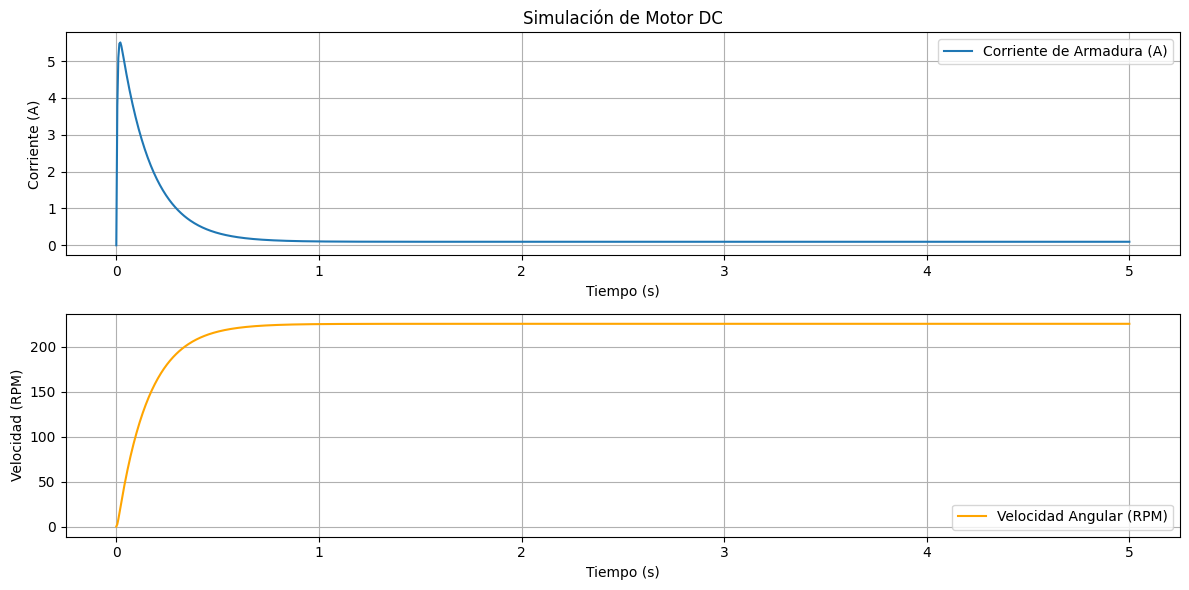

In [ ]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

def modelo_motor_dc(estado, t, V, R, L, J, B, K):
    """Modelo dinámico de motor DC"""
    i, w = estado  # corriente, velocidad angular

    di_dt = (V - R*i - K*w) / L
    dw_dt = (K*i - B*w) / J

    return [di_dt, dw_dt]

# Parámetros del motor
R = 2.0    # Resistencia armadura (Ω)
L = 0.01   # Inductancia armadura (H)
J = 0.02   # Inercia (kg·m²)
B = 0.002  # Fricción viscosa (N·m·s)
K = 0.5    # Constante de torque/fem (N·m/A o V·s/rad)

# Simulación
t = np.linspace(0, 5, 1000)  # 5 segundos
V = 12  # Voltaje aplicado

estado0 = [0, 0]  # [i0, w0]
sol = odeint(modelo_motor_dc, estado0, t, args=(V, R, L, J, B, K))

corriente = sol[:, 0]
velocidad = sol[:, 1] * 30 / np.pi  # Convertir a RPM

# Graficar los resultados
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(t, corriente, label='Corriente de Armadura (A)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Corriente (A)')
plt.title('Simulación de Motor DC')
plt.grid(True)
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(t, velocidad, label='Velocidad Angular (RPM)', color='orange')
plt.xlabel('Tiempo (s)')
plt.ylabel('Velocidad (RPM)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Crear un DataFrame con los resultados
df_resultados = pd.DataFrame({
    'Tiempo (s)': t,
    'Corriente (A)': corriente,
    'Velocidad (RPM)': velocidad
})

# Exportar a CSV
df_resultados.to_csv('simulacion_motor_dc.csv', index=False)

print('Resultados de la simulación exportados a "simulacion_motor_dc.csv"')

Resultados de la simulación exportados a "simulacion_motor_dc.csv"


## Procesamiento de Imágenes Térmicas (Visión por computador)

Busca una imagen usando "FLIR thermography inspection electrical gallery"



In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def detectar_puntos_calientes(imagen_termica_path, umbral_temp=80):
    """Detecta sobrecalentamiento en equipos eléctricos y lo visualiza."""
    # Cargar imagen térmica en escala de grises
    img_gray = cv2.imread(imagen_termica_path, cv2.IMREAD_GRAYSCALE)

    if img_gray is None:
        print(f"Error: No se pudo cargar la imagen de {imagen_termica_path}")
        return None

    # Convertir a BGR para poder dibujar contornos en color
    img_bgr = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2BGR)

    # Aplicar umbral para identificar áreas calientes
    # La temperatura en la imagen es simplemente el valor del píxel en escala de grises
    _, mascara = cv2.threshold(img_gray, umbral_temp, 255, cv2.THRESH_BINARY)

    # Encontrar contornos (puntos calientes)
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    print(f"Se encontraron {len(contornos)} puntos con sobrecalentamiento")

    # Medir temperaturas máximas y dibujar contornos
    for i, cnt in enumerate(contornos):
        # Crear una máscara temporal para el contorno actual
        mask = np.zeros_like(img_gray)
        cv2.drawContours(mask, [cnt], -1, 255, -1)

        # Calcular la temperatura máxima dentro del contorno
        temp_max = np.max(img_gray[mask == 255])
        print(f"Punto {i+1}: Temperatura máxima = {temp_max:.1f}°C")

        # Dibujar el contorno en la imagen BGR (en rojo)
        cv2.drawContours(img_bgr, [cnt], -1, (0, 0, 255), 2) # Rojo, grosor 2

        # Poner texto con la temperatura máxima cerca del contorno
        M = cv2.moments(cnt)
        if M["m00"] != 0:
            cX = int(M["m10"] / M["m00"])
            cY = int(M["m01"] / M["m00"])
            cv2.putText(img_bgr, f"{temp_max:.0f}C", (cX, cY), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1) # Amarillo

    return img_bgr

Imagen térmica de ejemplo guardada como 'dummy_thermal_image.png'
Se encontraron 3 puntos con sobrecalentamiento
Punto 1: Temperatura máxima = 120.0°C
Punto 2: Temperatura máxima = 90.0°C
Punto 3: Temperatura máxima = 85.0°C


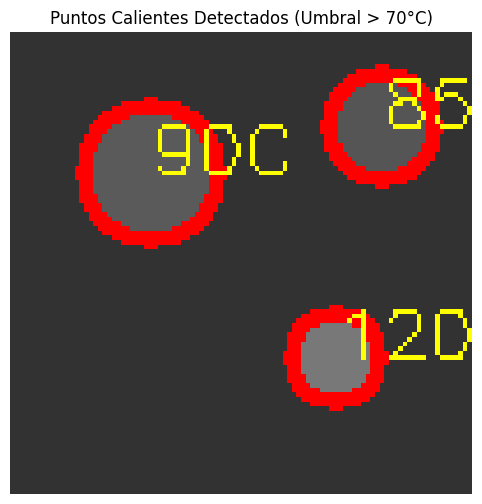

In [ ]:
# Generar una imagen térmica de ejemplo con puntos calientes simulados
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Crear una imagen en escala de grises de 100x100 píxeles, simulando temperaturas bajas (ej. 50°C)
img_dummy = np.full((100, 100), 50, dtype=np.uint8)

# Simular un punto caliente en el centro (ej. 90°C)
cv2.circle(img_dummy, (30, 30), 15, 90, -1)

# Simular otro punto caliente (ej. 120°C)
cv2.circle(img_dummy, (70, 70), 10, 120, -1)

# Simular un tercer punto caliente (ej. 85°C)
cv2.circle(img_dummy, (80, 20), 12, 85, -1)

# Guardar la imagen de ejemplo
thermal_image_filename = 'dummy_thermal_image.png'
cv2.imwrite(thermal_image_filename, img_dummy)

print(f"Imagen térmica de ejemplo guardada como '{thermal_image_filename}'")

# Usar la función para detectar y visualizar puntos calientes
umbral = 70 # Umbral de temperatura para detectar puntos calientes
img_con_hotspots = detectar_puntos_calientes(thermal_image_filename, umbral)

if img_con_hotspots is not None:
    # Mostrar la imagen con los puntos calientes detectados
    plt.figure(figsize=(8, 6))
    plt.imshow(cv2.cvtColor(img_con_hotspots, cv2.COLOR_BGR2RGB)) # Convertir BGR a RGB para matplotlib
    plt.title(f'Puntos Calientes Detectados (Umbral > {umbral}°C)')
    plt.axis('off')
    plt.show()


Se encontraron 61 puntos con sobrecalentamiento
Punto 1: Temperatura máxima = 255.0°C
Punto 2: Temperatura máxima = 167.0°C
Punto 3: Temperatura máxima = 252.0°C
Punto 4: Temperatura máxima = 245.0°C
Punto 5: Temperatura máxima = 248.0°C
Punto 6: Temperatura máxima = 248.0°C
Punto 7: Temperatura máxima = 247.0°C
Punto 8: Temperatura máxima = 248.0°C
Punto 9: Temperatura máxima = 244.0°C
Punto 10: Temperatura máxima = 245.0°C
Punto 11: Temperatura máxima = 248.0°C
Punto 12: Temperatura máxima = 252.0°C
Punto 13: Temperatura máxima = 162.0°C
Punto 14: Temperatura máxima = 255.0°C
Punto 15: Temperatura máxima = 255.0°C
Punto 16: Temperatura máxima = 255.0°C
Punto 17: Temperatura máxima = 255.0°C
Punto 18: Temperatura máxima = 255.0°C
Punto 19: Temperatura máxima = 160.0°C
Punto 20: Temperatura máxima = 154.0°C
Punto 21: Temperatura máxima = 233.0°C
Punto 22: Temperatura máxima = 157.0°C
Punto 23: Temperatura máxima = 152.0°C
Punto 24: Temperatura máxima = 255.0°C
Punto 25: Temperatura máx

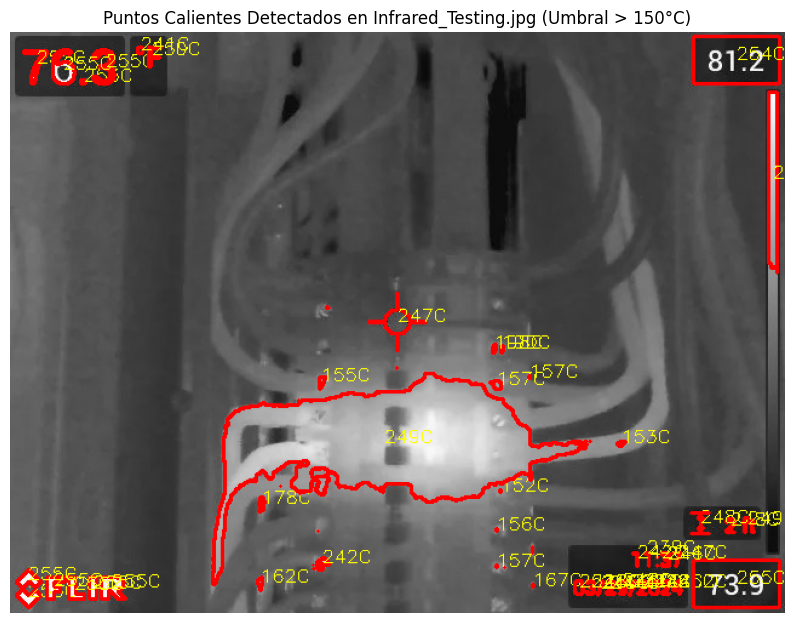

In [ ]:
thermal_image_real_filename = 'Infrared_Testing.jpg'
umbral_real = 150 # Puedes ajustar este umbral según la imagen y lo que consideres 'caliente'

img_con_hotspots_real = detectar_puntos_calientes(thermal_image_real_filename, umbral_real)

if img_con_hotspots_real is not None:
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(img_con_hotspots_real, cv2.COLOR_BGR2RGB)) # Convertir BGR a RGB para matplotlib
    plt.title(f'Puntos Calientes Detectados en {thermal_image_real_filename} (Umbral > {umbral_real}°C)')
    plt.axis('off')
    plt.show()